# EDA đợt E02 — AI4I 2020

Đợt E02 dùng 6 đầu vào gốc, tìm tham số bằng StratifiedKFold 3 fold trên train. Phân tích đặc trưng dùng train, kết quả mô hình dùng validation. Mốc chạy đầu của đợt là 04/11/2026 theo nhật ký dự án. Notebook tái lập EDA từ dữ liệu nguồn, log lịch sử và đối chiếu các lần chạy lại ngày 06/11. Kết quả CV và dự đoán từng mẫu lấy từ bộ tái lập results/final, có kiểm tra khớp log lịch sử trước khi phân tích.

## Hướng dẫn chạy

Chọn kernel Python đã cài requirements.txt, chọn Restart Kernel rồi Run All. Mã phân tích, bảng và biểu đồ hiển thị trực tiếp trong notebook. Notebook đọc data/ai4i2020.csv, các log trong experiments/history và kết quả đã lưu trong results/final. Phép chia phân tầng 70/15/15 dùng seed 42. Tập test dành cho đánh giá cuối sau khi chốt phương án.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Chạy từ thư mục gốc hoặc thư mục notebooks của dự án.
ROOT = next(
    folder for folder in [Path.cwd(), *Path.cwd().parents]
    if (folder / 'data/ai4i2020.csv').is_file()
)
NUM = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]',
]
modes = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']
colors = ['#537e99', '#c8553d']
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
})
df = pd.read_csv(ROOT / 'data/ai4i2020.csv')
assert set(['UDI', 'Product ID', 'Type', *NUM, 'Machine failure', *modes]).issubset(df.columns)
assert set(df['Machine failure'].unique()) == {0, 1}
assert df['UDI'].is_unique

# Tái lập phép chia phân tầng của lần baseline thứ nhất.
train_indices, remainder = train_test_split(
    df.index, test_size=0.30, stratify=df['Machine failure'], random_state=42,
)
validation_indices, test_indices = train_test_split(
    remainder, test_size=0.50,
    stratify=df.loc[remainder, 'Machine failure'], random_state=42,
)
train = df.loc[train_indices].copy()
split = pd.concat([
    pd.DataFrame({'row_index': indices, 'split': name})
    for indices, name in [
        (train_indices, 'train'),
        (validation_indices, 'validation'),
        (test_indices, 'test'),
    ]
], ignore_index=True)
baseline_path = ROOT / 'experiments/history/three_rounds_2026-11-04.csv'
RUN = 'E02'
ENGINEERED = False
TUNED = True
baseline = pd.read_csv(baseline_path).query('run == @RUN').copy()
assert split['row_index'].is_unique and len(split) == len(df)
assert len(baseline) == 4
assert set(baseline['model']) == {'LogisticRegression', 'DecisionTree', 'RandomForest', 'GradientBoosting'}
assert baseline['evaluation_set'].eq('validation').all() and baseline['seed'].eq(42).all()
validation_y = df.loc[validation_indices, 'Machine failure']
assert (baseline[['tn', 'fp', 'fn', 'tp']].sum(axis=1) == len(validation_y)).all()
assert (baseline['fn'] + baseline['tp'] == validation_y.sum()).all()
assert (baseline['tn'] + baseline['fp'] == (validation_y == 0).sum()).all()
for metric, numerator, denominator in [
    ('precision', baseline['tp'], baseline['tp'] + baseline['fp']),
    ('recall', baseline['tp'], baseline['tp'] + baseline['fn']),
    ('f1', 2*baseline['tp'], 2*baseline['tp'] + baseline['fp'] + baseline['fn'])
]:
    expected = numerator.div(denominator.replace(0, np.nan)).fillna(0)
    assert np.allclose(baseline[metric], expected)
assert baseline['engineered_features'].eq(ENGINEERED).all()
assert baseline['tuned'].eq(TUNED).all()

## 1. Từ điển dữ liệu

Một dòng tương ứng một quan sát vận hành. Đầu vào gốc gồm Type và 5 biến số. Các cờ loại lỗi dùng để mô tả nhãn. Đưa các cờ này vào đầu vào có thể gây rò rỉ thông tin nhãn.

In [2]:
meanings = {
    'UDI': 'Định danh dòng', 'Product ID': 'Định danh sản phẩm', 'Type': 'Nhóm chất lượng L/M/H',
    'Air temperature [K]': 'Nhiệt độ không khí, Kelvin',
    'Process temperature [K]': 'Nhiệt độ quá trình, Kelvin',
    'Rotational speed [rpm]': 'Tốc độ quay, vòng/phút',
    'Torque [Nm]': 'Mô-men xoắn, Nm', 'Tool wear [min]': 'Độ mòn theo thời gian, phút',
    'Machine failure': 'Nhãn tổng, 1 là có lỗi', 'TWF': 'Cờ lỗi mòn dụng cụ',
    'HDF': 'Cờ lỗi tản nhiệt', 'PWF': 'Cờ lỗi công suất',
    'OSF': 'Cờ lỗi quá tải', 'RNF': 'Cờ lỗi ngẫu nhiên'
}
roles = {col: 'Đầu vào' for col in ['Type', *NUM]}
roles.update({col: 'Mô tả loại lỗi' for col in modes})
roles['Machine failure'] = 'Nhãn'
table = pd.DataFrame([{'Cột': col, 'Kiểu': str(df[col].dtype), 'Ý nghĩa': meanings[col],
                       'Vai trò': roles.get(col, 'Định danh')} for col in df.columns])
table

,Cột,Kiểu,Ý nghĩa,Vai trò
0,UDI,int64,Định danh dòng,Định danh
1,Product ID,str,Định danh sản phẩm,Định danh
2,Type,str,Nhóm chất lượng L/M/H,Đầu vào
3,Air temperature [K],float64,"Nhiệt độ không khí, Kelvin",Đầu vào
4,Process temperature [K],float64,"Nhiệt độ quá trình, Kelvin",Đầu vào
5,Rotational speed [rpm],int64,"Tốc độ quay, vòng/phút",Đầu vào
6,Torque [Nm],float64,"Mô-men xoắn, Nm",Đầu vào
7,Tool wear [min],int64,"Độ mòn theo thời gian, phút",Đầu vào
8,Machine failure,int64,"Nhãn tổng, 1 là có lỗi",Nhãn
9,TWF,int64,Cờ lỗi mòn dụng cụ,Mô tả loại lỗi


## 2. Chất lượng dữ liệu và phép chia

Kiểm tra thiếu, trùng dòng, trùng UDI và giá trị số không hữu hạn trên nguồn. Bảng chia ghi số lượng và tỷ lệ nhãn để đối chiếu tính phân tầng.

In [3]:
quality = {
    'Số dòng': len(df), 'Số cột': len(df.columns), 'Ô thiếu': int(df.isna().sum().sum()),
    'Dòng trùng toàn bộ': int(df.duplicated().sum()), 'UDI trùng': int(df['UDI'].duplicated().sum()),
    'Số không hữu hạn': int((~np.isfinite(df[NUM].to_numpy())).sum()),
    'Nhãn khác OR của cờ lỗi': int((df['Machine failure'] != df[modes].max(axis=1)).sum())
}
table = pd.DataFrame(quality.items(), columns=['Kiểm tra', 'Kết quả'])
table

,Kiểm tra,Kết quả
0,Số dòng,10000
1,Số cột,14
2,Ô thiếu,0
3,Dòng trùng toàn bộ,0
4,UDI trùng,0
5,Số không hữu hạn,0
6,Nhãn khác OR của cờ lỗi,27


In [4]:
table = split.merge(df[['Machine failure']], left_on='row_index', right_index=True)
table = table.groupby('split')['Machine failure'].agg(['count', 'sum', 'mean'])
table = table.reindex(['train', 'validation', 'test']).reset_index()
table.columns = ['Tập', 'Số mẫu', 'Số lỗi', 'Tỷ lệ lỗi']
table

,Tập,Số mẫu,Số lỗi,Tỷ lệ lỗi
0,train,7000,237,0.033857
1,validation,1500,51,0.034000
2,test,1500,51,0.034000


## Nhận xét chất lượng

Nguồn có 10,000 dòng và 14 cột, 0 ô thiếu, 0 dòng trùng toàn bộ và 0 UDI trùng. Có 27 dòng mà nhãn tổng khác OR của 5 cờ loại lỗi. Giữ nhãn nguồn và ghi nhận sự khác biệt khi diễn giải các loại lỗi.

## 3. Mất cân bằng nhãn trên train

Biểu đồ ghi số lượng và tỷ lệ của hai lớp.

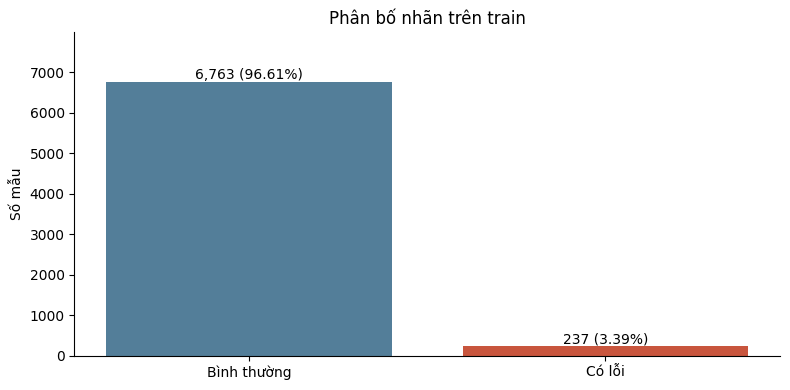

In [5]:
counts = train['Machine failure'].value_counts().reindex([0, 1], fill_value=0)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(['Bình thường', 'Có lỗi'], counts, color=colors)
for i, n in enumerate(counts):
    ax.text(i, n, f'{n:,} ({n/len(train):.2%})', ha='center', va='bottom')
ax.set(title='Phân bố nhãn trên train', ylabel='Số mẫu', ylim=(0, counts.max()*1.18))
fig.tight_layout()
plt.show()
plt.close(fig)

## Nhận xét về nhãn

Train có 237 mẫu lỗi trên 7,000 mẫu (3.39%). Dự đoán tất cả là bình thường trên train đạt accuracy 96.61% và recall lớp lỗi bằng 0. Sử dụng precision, recall, F1 và số FN/FP để đánh giá khả năng phát hiện lỗi.

## 4. Thống kê và phân bố các biến số

Thống kê theo đơn vị gốc. Histogram thể hiện phân bố chung trên train. Các biến có thang đo khác nhau là cơ sở để chuẩn hóa trong pipeline của Logistic Regression.

In [6]:
table = train[NUM].describe().T.reset_index().rename(columns={'index': 'Feature'})
table['skewness'] = train[NUM].skew().to_numpy()
table

,Feature,count,mean,std,min,25%,50%,75%,max,skewness
0,Air temperature [K],7000.0,300.014357,2.002674,295.3,298.3,300.1,301.5,304.5,0.114420
1,Process temperature [K],7000.0,310.006629,1.481637,305.7,308.8,310.1,311.1,313.8,0.031761
2,Rotational speed [rpm],7000.0,1539.237429,180.237529,1168.0,1423.0,1504.0,1614.0,2886.0,2.024199
3,Torque [Nm],7000.0,40.001300,10.006015,3.8,33.2,40.1,46.8,76.6,0.003651
4,Tool wear [min],7000.0,107.623571,63.863906,0.0,52.0,107.0,163.0,253.0,0.031793


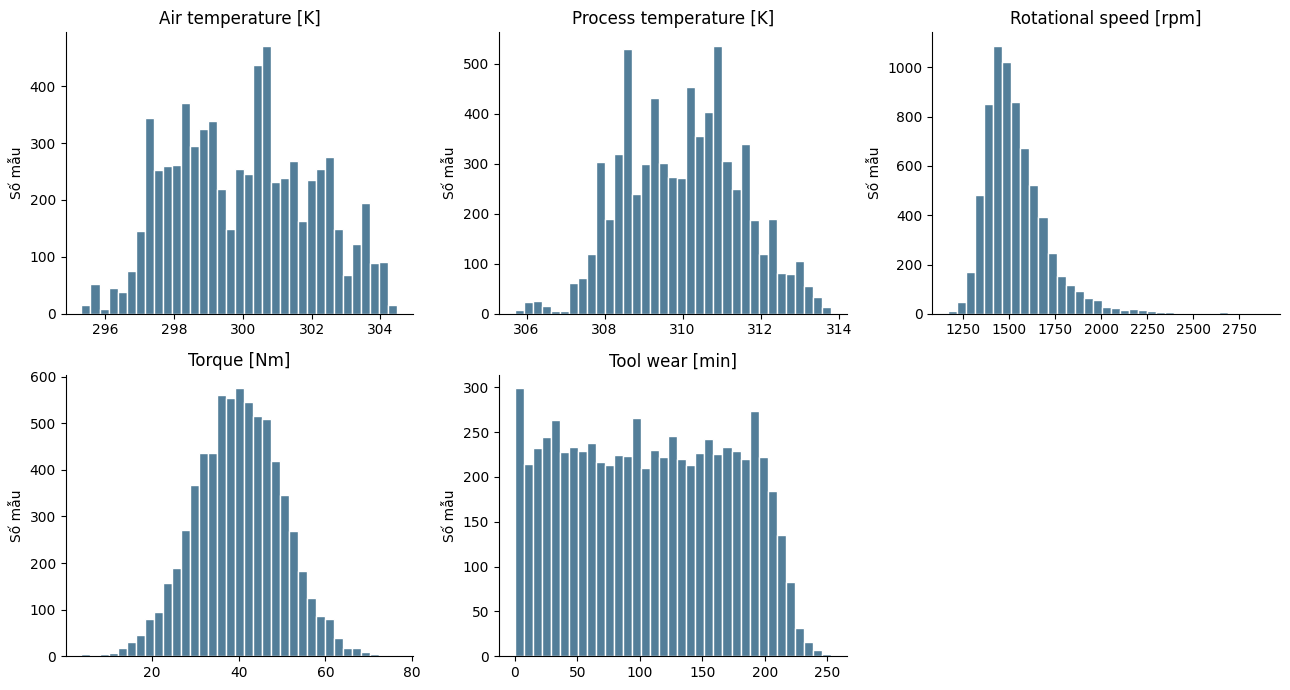

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for col, ax in zip(NUM, axes.flat):
    ax.hist(train[col], bins=35, color=colors[0], edgecolor='white')
    ax.set(title=col, ylabel='Số mẫu')
axes.flat[-1].axis('off')
fig.tight_layout()
plt.show()
plt.close(fig)

## Nhận xét phân bố

Rotational speed [rpm] có độ lệch tuyệt đối lớn nhất trong 5 biến với skewness 2.024. Tốc độ quay trên train nằm trong khoảng 1168–2886 rpm. Miền giá trị và độ lệch này giúp kiểm tra dữ liệu đầu vào trước khi huấn luyện.

## 5. Máy lỗi và máy bình thường

Boxplot hiển thị cả điểm ngoài râu. Bảng trung vị định lượng chênh lệch giữa hai nhóm.

In [8]:
table = train.groupby('Machine failure')[NUM].median().T
table.columns = ['Trung vị bình thường', 'Trung vị có lỗi']
table['Chênh lệch lỗi - bình thường'] = table.iloc[:, 1] - table.iloc[:, 0]
table = table.reset_index().rename(columns={'index': 'Feature'})
table

,Feature,Trung vị bình thường,Trung vị có lỗi,Chênh lệch lỗi - bình thường
0,Air temperature [K],300.1,301.6,1.5
1,Process temperature [K],310.0,310.4,0.4
2,Rotational speed [rpm],1507.0,1365.0,-142.0
3,Torque [Nm],39.8,53.3,13.5
4,Tool wear [min],106.0,166.0,60.0


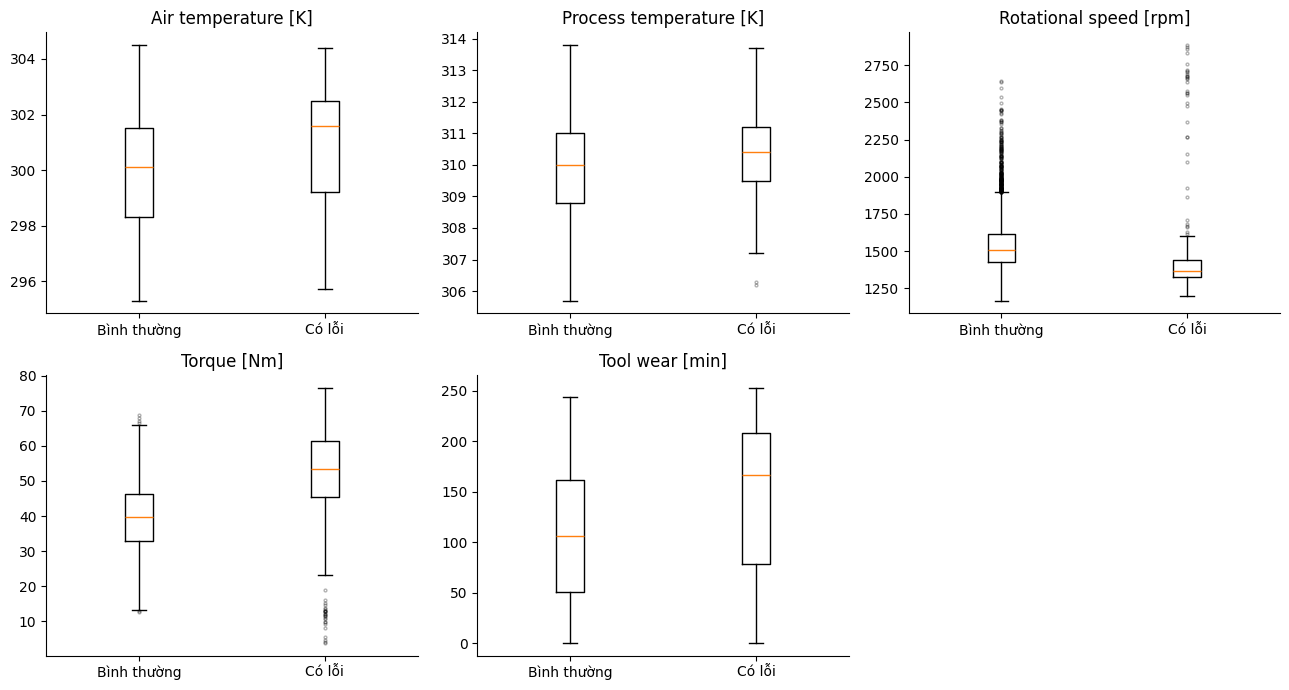

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for col, ax in zip(NUM, axes.flat):
    ax.boxplot([train.loc[train['Machine failure'] == c, col] for c in (0, 1)],
               tick_labels=['Bình thường', 'Có lỗi'], showfliers=True,
               flierprops={'markersize': 2, 'alpha': 0.3})
    ax.set(title=col)
axes.flat[-1].axis('off')
fig.tight_layout()
plt.show()
plt.close(fig)

## Nhận xét khác biệt giữa hai nhóm

Mô-men trung vị là 39.80 Nm ở nhóm bình thường và 53.30 Nm ở nhóm lỗi. Độ mòn trung vị tương ứng là 106.0 và 166.0 phút. Các hộp và râu có vùng chồng lấp. Việc kết hợp nhiều thông số cần được kiểm chứng bằng mô hình.

## 6. Điểm cực trị theo quy tắc IQR

Đánh dấu giá trị dưới Q1 − 1,5×IQR hoặc trên Q3 + 1,5×IQR trên train. Một dòng có thể được đánh dấu ở nhiều biến. Giữ các điểm này để bảo toàn tình huống vận hành cực trị.

In [10]:
outlier_rows = []
for col in NUM:
    q1, q3 = train[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    mask = (train[col] < q1 - 1.5*iqr) | (train[col] > q3 + 1.5*iqr)
    outlier_rows.append({'Feature': col, 'Lower': q1 - 1.5*iqr, 'Upper': q3 + 1.5*iqr,
                         'Flagged': int(mask.sum()),
                         'Failure rate flagged': train.loc[mask, 'Machine failure'].mean(),
                         'Failure rate other': train.loc[~mask, 'Machine failure'].mean()})
table = pd.DataFrame(outlier_rows)
table

,Feature,Lower,Upper,Flagged,Failure rate flagged,Failure rate other
0,Air temperature [K],293.50,306.30,0,NaN,0.033857
1,Process temperature [K],305.35,314.55,0,NaN,0.033857
2,Rotational speed [rpm],1136.50,1900.50,284,0.095070,0.031269
3,Torque [Nm],12.80,67.20,51,0.921569,0.027342
4,Tool wear [min],-114.50,329.50,0,NaN,0.033857


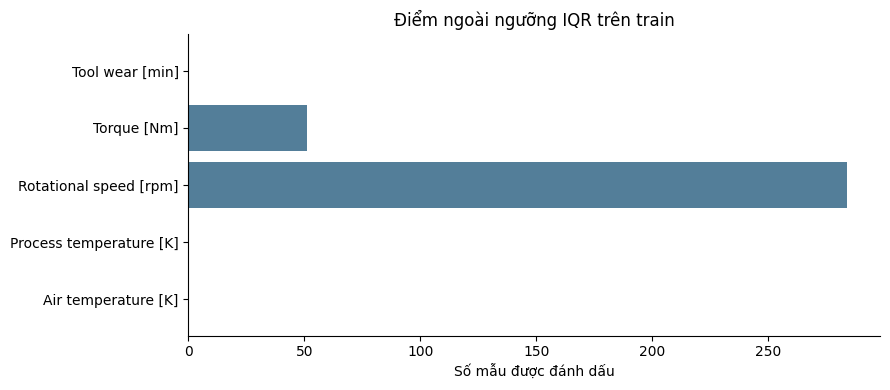

In [11]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(table['Feature'], table['Flagged'], color=colors[0])
ax.set(xlabel='Số mẫu được đánh dấu', title='Điểm ngoài ngưỡng IQR trên train')
fig.tight_layout()
plt.show()
plt.close(fig)

## Nhận xét điểm cực trị

Rotational speed [rpm] có nhiều điểm ngoài ngưỡng IQR nhất với 284 mẫu. Tỷ lệ lỗi ở nhóm này là 9.51%, ở nhóm còn lại là 3.13%. Xóa tự động điểm ngoài IQR có thể làm mất mẫu lỗi cần học.

## 7. Tỷ lệ lỗi theo Type

Thanh sai số là khoảng Wilson 95% cho tỷ lệ nhị thức. Số mẫu từng nhóm giúp diễn giải độ bất định của tỷ lệ.

In [12]:
table = train.groupby('Type')['Machine failure'].agg(['count', 'sum', 'mean']).reset_index()
table.columns = ['Type', 'Samples', 'Failures', 'Failure rate']
n, p = table['Samples'], table['Failure rate']
z = 1.959963984540054
center = (p + z*z/(2*n)) / (1 + z*z/n)
half = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / (1 + z*z/n)
table['Wilson lower'], table['Wilson upper'] = center-half, center+half
table

,Type,Samples,Failures,Failure rate,Wilson lower,Wilson upper
0,H,705,14,0.019858,0.011865,0.033055
1,L,4217,175,0.041499,0.035885,0.047947
2,M,2078,48,0.023099,0.017467,0.030492


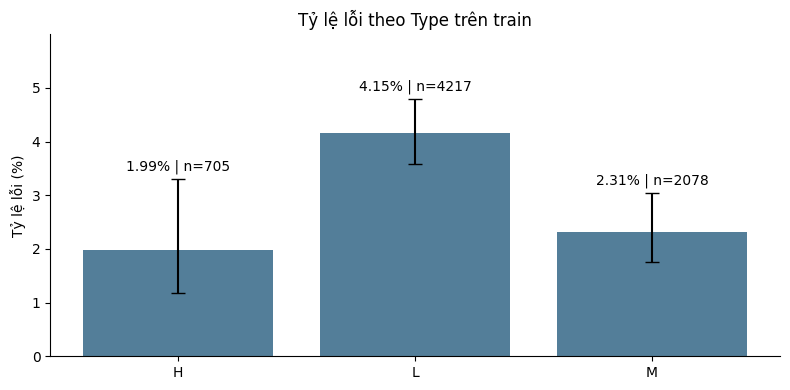

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
p = table['Failure rate']*100
errors = np.array([p-table['Wilson lower']*100, table['Wilson upper']*100-p])
ax.bar(table['Type'], p, color=colors[0], yerr=errors, capsize=5)
for i, row in table.iterrows():
    ax.text(i, row['Wilson upper']*100+0.15,
            f"{row['Failure rate']:.2%} | n={row['Samples']}", ha='center')
ax.set(ylabel='Tỷ lệ lỗi (%)', title='Tỷ lệ lỗi theo Type trên train',
       ylim=(0, table['Wilson upper'].max()*100+1.2))
fig.tight_layout()
plt.show()
plt.close(fig)

## Nhận xét theo Type

Tỷ lệ lỗi quan sát được là H 1.99% (14/705), L 4.15% (175/4217), M 2.31% (48/2078). Các khoảng Wilson thể hiện bất định trong mẫu train.

## 8. Quan hệ giữa các thông số

Scatter dùng toàn bộ train, các mẫu lỗi có màu đỏ. Độ trong suốt giúp đọc vùng dày mẫu.

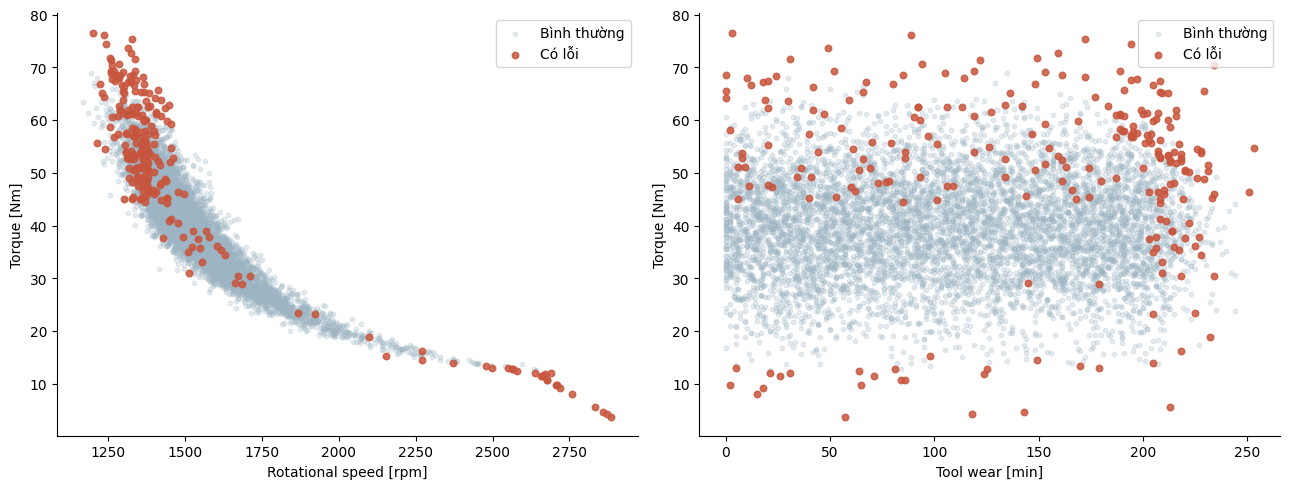

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, x, y in [(axes[0], NUM[2], NUM[3]), (axes[1], NUM[4], NUM[3])]:
    for label, color, name in [(0, '#9cb4c3', 'Bình thường'), (1, colors[1], 'Có lỗi')]:
        part = train.loc[train['Machine failure'] == label]
        ax.scatter(part[x], part[y], s=10 if label == 0 else 22,
                   alpha=0.25 if label == 0 else 0.85, c=color, label=name)
    ax.set(xlabel=x, ylabel=y)
    ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)

## 9. Tương quan giữa các biến số

Heatmap Pearson mô tả liên hệ tuyến tính giữa từng cặp biến trên train.

In [15]:
corr = train[NUM].corr()
table = corr.reset_index().rename(columns={'index': 'Feature'})
table

,Feature,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,Air temperature [K],1.000000,0.877527,0.024087,-0.016299,0.012548
1,Process temperature [K],0.877527,1.000000,0.018345,-0.015737,0.014224
2,Rotational speed [rpm],0.024087,0.018345,1.000000,-0.873847,-0.002260
3,Torque [Nm],-0.016299,-0.015737,-0.873847,1.000000,-0.004357
4,Tool wear [min],0.012548,0.014224,-0.002260,-0.004357,1.000000


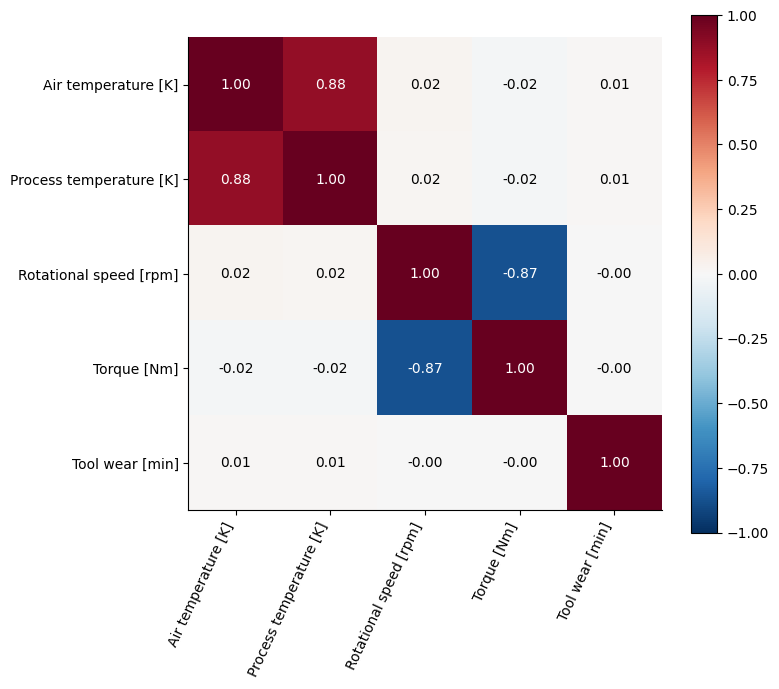

In [16]:
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(range(len(NUM)), NUM, rotation=65, ha='right')
ax.set_yticks(range(len(NUM)), NUM)
for i in range(len(NUM)):
    for j in range(len(NUM)):
        ax.text(j, i, f'{corr.iloc[i,j]:.2f}', ha='center', va='center',
                color='white' if abs(corr.iloc[i,j]) > 0.6 else 'black')
fig.colorbar(im, ax=ax)
fig.tight_layout()
plt.show()
plt.close(fig)

## Nhận xét quan hệ đặc trưng

Tương quan tốc độ quay và mô-men là -0.874. Tương quan hai nhiệt độ là 0.878. Scatter cho thấy tốc độ và mô-men biến thiên ngược chiều, lỗi xuất hiện ở nhiều vùng vận hành. Các tương tác giữa thông số là giả thuyết để kiểm chứng bằng CV trên train.

## 10. Các cờ loại lỗi trên train

Đếm số dòng có từng cờ bằng 1. Một dòng có thể có nhiều cờ cùng bật nên các số đếm có thể chồng lấp.

In [17]:
table = train[modes].sum().rename('Count').reset_index().rename(columns={'index': 'Flag'})
table['Percent of train'] = table['Count']/len(train)*100
table

,Flag,Count,Percent of train
0,TWF,33,0.471429
1,HDF,73,1.042857
2,PWF,72,1.028571
3,OSF,71,1.014286
4,RNF,13,0.185714


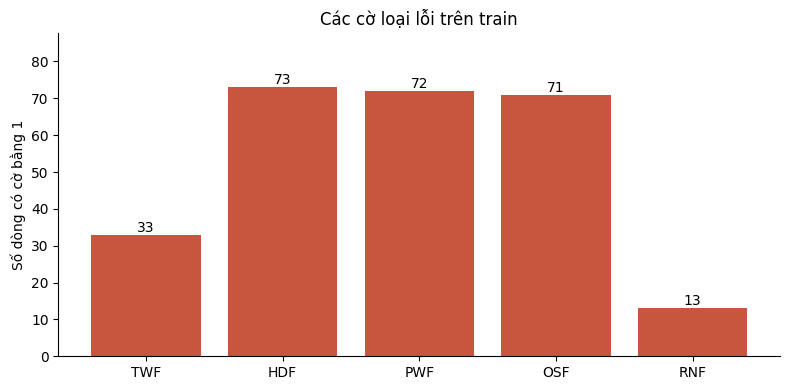

In [18]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(table['Flag'], table['Count'], color=colors[1])
for i, n in enumerate(table['Count']):
    ax.text(i, n, str(n), ha='center', va='bottom')
ax.set(title='Các cờ loại lỗi trên train', ylabel='Số dòng có cờ bằng 1', ylim=(0, table['Count'].max()*1.2))
fig.tight_layout()
plt.show()
plt.close(fig)

## Nhận xét loại lỗi

Cờ xuất hiện nhiều nhất trên train là HDF với 73 dòng. Có 19 dòng train có nhãn tổng khác OR của các cờ. Đọc số đếm cờ cùng kết quả kiểm tra nhãn khi mô tả dữ liệu.

## 11. Đối chiếu lịch sử và các lần chạy lại

Bảng ghi độ đo từng mô hình từ log ngày 04/11, hai lần kiểm tra ngày 06/11 và bộ kết quả cuối.
Kiểm tra bên dưới đối chiếu số đếm nhầm lẫn và các độ đo. Thời gian fit thay đổi theo lần chạy và môi trường.

In [19]:
sources = {
    '04/11 — lần đầu': baseline_path,
    '06/11 — run_01': ROOT / 'experiments/history/2026-11-06_run_01.csv',
    '06/11 — refactor_check': ROOT / 'experiments/history/2026-11-06_refactor_check.csv',
    '06/11 — final': ROOT / 'results/final/experiment_log.csv',
}
compare_columns = ['precision', 'recall', 'f1', 'roc_auc', 'average_precision', 'tn', 'fp', 'fn', 'tp']
reference = baseline.set_index('model').sort_index()
history = []
for name, path in sources.items():
    current = pd.read_csv(path).query('run == @RUN').set_index('model').sort_index()
    assert current.index.equals(reference.index)
    assert np.allclose(current[compare_columns], reference[compare_columns])
    current = current.reset_index()
    current.insert(0, 'Lần chạy', name)
    history.append(current)
history = pd.concat(history, ignore_index=True)
history[['Lần chạy', 'model', 'f1', 'recall', 'fp', 'fn', 'fit_seconds']]

,Lần chạy,model,f1,recall,fp,fn,fit_seconds
0,04/11 — lần đầu,DecisionTree,0.536585,0.647059,39,18,1.401949
1,04/11 — lần đầu,GradientBoosting,0.739130,0.666667,7,17,18.850952
2,04/11 — lần đầu,LogisticRegression,0.230530,0.725490,233,14,4.975000
3,04/11 — lần đầu,RandomForest,0.606742,0.529412,11,24,23.242930
4,06/11 — run_01,DecisionTree,0.536585,0.647059,39,18,0.647022
5,06/11 — run_01,GradientBoosting,0.739130,0.666667,7,17,9.397723
6,06/11 — run_01,LogisticRegression,0.230530,0.725490,233,14,4.287829
7,06/11 — run_01,RandomForest,0.606742,0.529412,11,24,12.837581
8,06/11 — refactor_check,DecisionTree,0.536585,0.647059,39,18,0.605547
9,06/11 — refactor_check,GradientBoosting,0.739130,0.666667,7,17,9.121691


## 12. Kết quả validation và so sánh baseline E00

Precision = TP/(TP+FP), recall = TP/(TP+FN), F1 = 2TP/(2TP+FP+FN).
FN là lỗi bị bỏ sót, FP là báo động giả. So sánh với cùng thuật toán trong lần baseline đầu tiên.

In [20]:
summary = baseline[['model', 'precision', 'recall', 'f1', 'roc_auc', 'average_precision',
                    'tn', 'fp', 'fn', 'tp', 'train_f1', 'train_validation_f1_gap']].copy()
initial = pd.read_csv(ROOT / 'experiments/history/comparison_5_models.csv')
summary = summary.merge(initial[['model', 'f1']].rename(columns={'f1': 'E00 F1'}), on='model', validate='one_to_one')
summary['F1 change vs E00'] = summary['f1'] - summary['E00 F1']
summary

,model,precision,recall,f1,roc_auc,average_precision,tn,fp,fn,tp,train_f1,train_validation_f1_gap,E00 F1,F1 change vs E00
0,LogisticRegression,0.137037,0.725490,0.230530,0.874856,0.384816,1216,233,14,37,0.242236,0.011706,0.229814,0.000716
1,DecisionTree,0.458333,0.647059,0.536585,0.815322,0.488891,1410,39,18,33,0.734884,0.198298,0.453988,0.082598
2,RandomForest,0.710526,0.529412,0.606742,0.968991,0.642202,1438,11,24,27,0.989562,0.382820,0.590909,0.015832
3,GradientBoosting,0.829268,0.666667,0.739130,0.983565,0.806779,1442,7,17,34,0.935123,0.195993,0.705882,0.033248


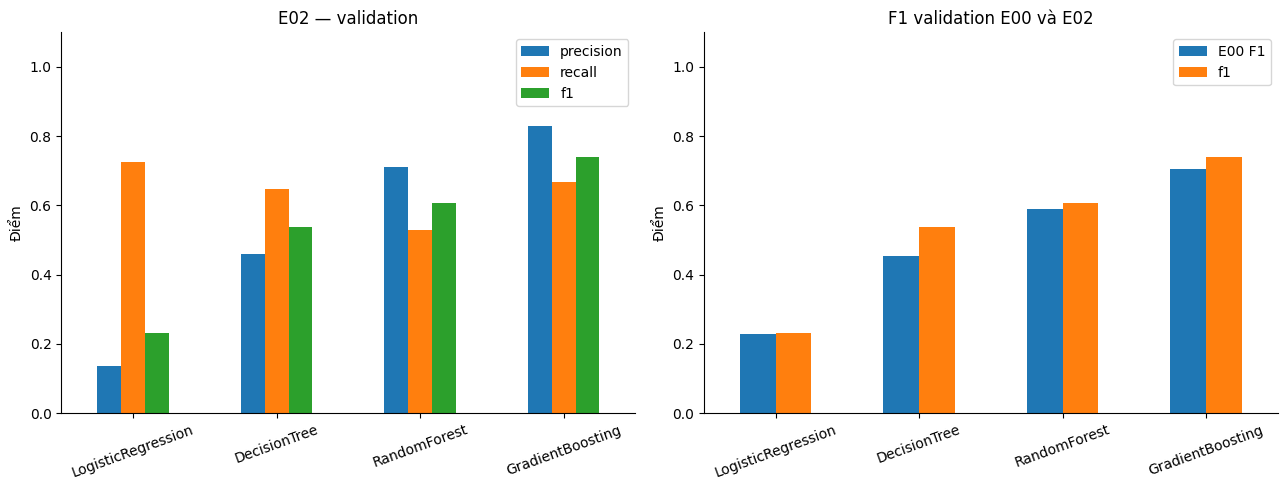

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
baseline.set_index('model')[['precision', 'recall', 'f1']].plot.bar(ax=axes[0], rot=20)
summary.set_index('model')[['E00 F1', 'f1']].plot.bar(ax=axes[1], rot=20)
for ax in axes:
    ax.set(ylim=(0, 1.1), xlabel='', ylabel='Điểm')
axes[0].set_title(f'{RUN} — validation')
axes[1].set_title(f'F1 validation E00 và {RUN}')
fig.tight_layout()
plt.show()
plt.close(fig)

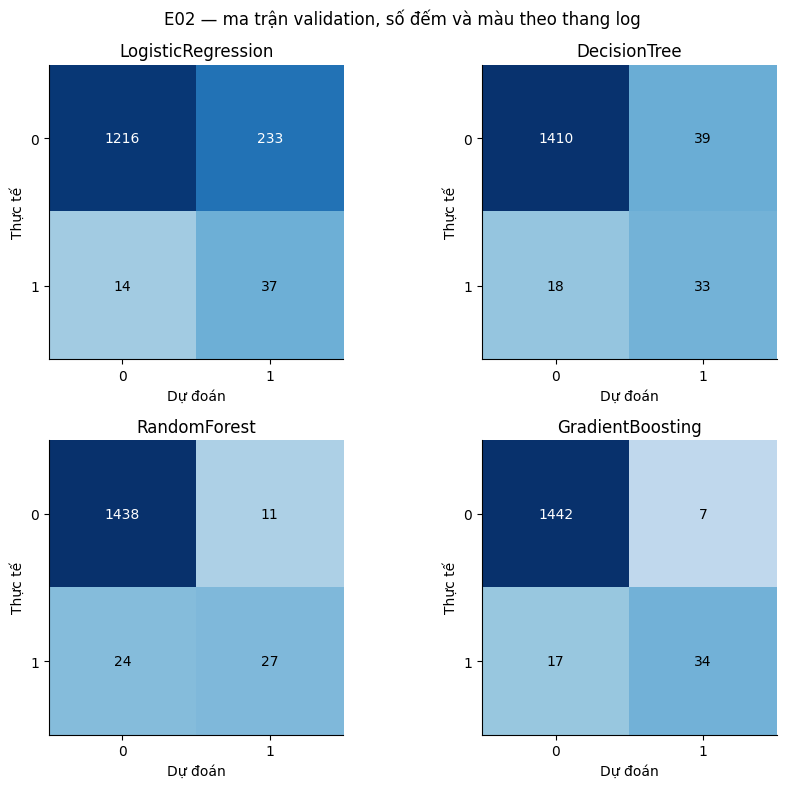

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(9, 8))
for ax, (_, row) in zip(axes.flat, baseline.iterrows()):
    matrix = np.array([[row['tn'], row['fp']], [row['fn'], row['tp']]], dtype=int)
    ax.imshow(matrix, cmap='Blues', norm=matplotlib.colors.LogNorm(vmin=1, vmax=1500))
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(matrix[i,j]), ha='center', va='center',
                    color='white' if matrix[i,j] > 100 else 'black')
    ax.set(title=row['model'], xlabel='Dự đoán', ylabel='Thực tế',
           xticks=[0, 1], yticks=[0, 1], xticklabels=['0', '1'], yticklabels=['0', '1'])
fig.suptitle(f'{RUN} — ma trận validation, số đếm và màu theo thang log')
fig.tight_layout()
plt.show()
plt.close(fig)

## 13. Kết quả tìm tham số trên train

Các file cv_results.csv thuộc bộ tái lập ngày 06/11. mean_test_f1 trong file là F1 trung bình
trên fold giữ lại của CV nội bộ train. Thanh sai số là độ lệch chuẩn qua 3 fold.
Việc chọn tham số dựa vào F1 CV. Điểm validation dùng để đánh giá cấu hình sau tìm kiếm.

In [23]:
cv_tables = []
for model in baseline['model']:
    cv = pd.read_csv(ROOT / f'results/final/{RUN}/{model}/cv_results.csv')
    winner = cv.sort_values('rank_test_f1', kind='stable').iloc[0]
    logged = baseline.set_index('model').loc[model]
    assert np.isclose(winner['mean_test_f1'], logged['cv_mean_f1'])
    assert np.isclose(winner['std_test_f1'], logged['cv_std_f1'])
    cv_tables.append({'model': model, 'Candidates': len(cv),
                      'CV mean F1': winner['mean_test_f1'], 'CV std F1': winner['std_test_f1'],
                      'Validation F1': logged['f1'], 'Selected parameters': winner['params']})
cv_summary = pd.DataFrame(cv_tables)
cv_summary

,model,Candidates,CV mean F1,CV std F1,Validation F1,Selected parameters
0,LogisticRegression,3,0.241365,0.011790,0.230530,{'model__C': 0.1}
1,DecisionTree,6,0.491613,0.026713,0.536585,"{'model__max_depth': 10, 'model__min_samples_l..."
2,RandomForest,8,0.608081,0.015630,0.606742,"{'model__max_depth': None, 'model__min_samples..."
3,GradientBoosting,8,0.693191,0.018774,0.739130,"{'model__learning_rate': 0.1, 'model__max_dept..."


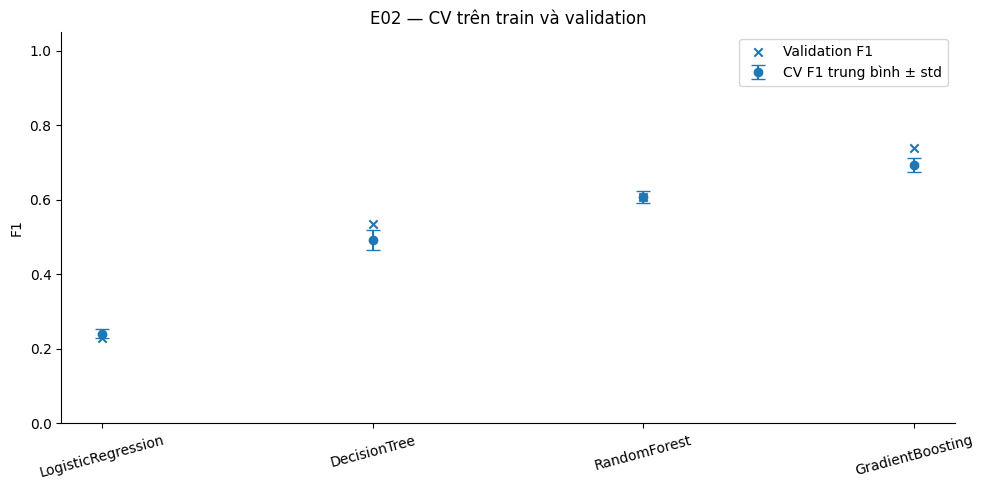

In [24]:
fig, ax = plt.subplots(figsize=(10, 5))
positions = np.arange(len(cv_summary))
ax.errorbar(positions, cv_summary['CV mean F1'], yerr=cv_summary['CV std F1'],
            fmt='o', capsize=5, label='CV F1 trung bình ± std')
ax.scatter(positions, cv_summary['Validation F1'], marker='x', label='Validation F1')
ax.set(xticks=positions, xticklabels=cv_summary['model'], ylim=(0, 1.05), ylabel='F1',
       title=f'{RUN} — CV trên train và validation')
ax.tick_params(axis='x', rotation=15)
ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)

## 14. Phân tích lỗi của mô hình có F1 cao nhất

Dự đoán từng mẫu lấy từ bộ tái lập ngày 06/11. Kiểm tra index, nhãn nguồn và TN/FP/FN/TP
khớp log đợt đầu trước khi xem mẫu bỏ sót. Việc kiểm tra này đối chiếu kết quả đã lưu.

In [25]:
best = baseline.sort_values('f1', ascending=False).iloc[0]
predictions_path = ROOT / f"results/final/{RUN}/{best['model']}/validation_predictions.csv"
predictions = pd.read_csv(predictions_path)
assert predictions['row_index'].is_unique
assert set(predictions['row_index']) == set(validation_indices)
assert np.array_equal(predictions['actual'], df.loc[predictions['row_index'], 'Machine failure'])
actual, predicted = predictions['actual'], predictions['predicted']
observed = [int(((actual == a) & (predicted == p)).sum()) for a, p in [(0,0), (0,1), (1,0), (1,1)]]
assert observed == [int(best[col]) for col in ['tn', 'fp', 'fn', 'tp']]
details = predictions.merge(df, left_on='row_index', right_index=True, validate='one_to_one', suffixes=('', '_source'))
errors = details.loc[details['actual'] != details['predicted']]
errors[['UDI', 'Type', *NUM, 'actual', 'predicted', 'failure_probability', 'outcome']]

,UDI,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],actual,predicted,failure_probability,outcome
269,7850,M,300.3,311.7,1374,47.9,222,1,0,0.184009,FN
321,3795,M,302.2,310.8,1356,48.3,36,0,1,0.614251,FP
326,1124,H,296.6,307.7,1386,62.3,100,1,0,0.438380,FN
347,7885,L,300.8,312.4,1465,59.1,91,1,0,0.039741,FN
385,3807,M,302.3,310.9,1360,44.0,67,1,0,0.455381,FN
433,2672,M,299.7,309.3,1399,41.9,221,1,0,0.049038,FN
522,8004,M,300.8,312.0,1274,67.3,159,0,1,0.844733,FP
617,3810,L,302.2,310.8,1350,56.6,76,0,1,0.683123,FP
626,7088,L,300.6,310.3,1648,30.5,217,1,0,0.052116,FN
657,9445,L,298.1,308.9,2136,15.9,78,0,1,0.694782,FP


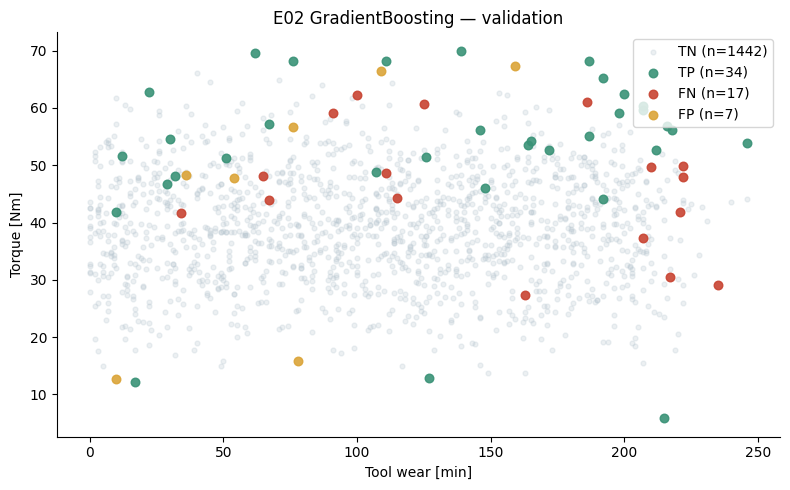

In [26]:
fig, ax = plt.subplots(figsize=(8, 5))
for outcome, color in [('TN', '#b5c4ce'), ('TP', '#3a9277'), ('FN', '#c84432'), ('FP', '#dba438')]:
    part = details.loc[details['outcome'] == outcome]
    ax.scatter(part['Tool wear [min]'], part['Torque [Nm]'], label=f'{outcome} (n={len(part)})',
               c=color, s=12 if outcome == 'TN' else 38, alpha=0.25 if outcome == 'TN' else 0.9)
ax.set(xlabel='Tool wear [min]', ylabel='Torque [Nm]', title=f"{RUN} {best['model']} — validation")
ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)

## Kết luận theo số liệu

In [27]:
from IPython.display import Markdown, display
delta = summary.set_index('model').loc[best['model'], 'F1 change vs E00']
display(Markdown(
    f"**{RUN} — {best['model']}** đạt F1 cao nhất {best['f1']:.4f}, "
    f"precision {best['precision']:.4f}, recall {best['recall']:.4f}. "
    f"Phát hiện {int(best['tp'])}/{int(best['tp']+best['fn'])} lỗi, "
    f"bỏ sót {int(best['fn'])} và có {int(best['fp'])} báo động giả. "
    f"F1 thay đổi {delta:+.4f} so với E00 cùng thuật toán. "
    'Các log chạy lại khớp độ đo và số đếm của đợt đầu. '
    'Kết quả phản ánh một phép chia seed 42 trên dữ liệu mô phỏng. '
    'Các quan sát từ validation và lỗi dự đoán giúp định hướng thí nghiệm tiếp theo trên train/CV.'
))

**E02 — GradientBoosting** đạt F1 cao nhất 0.7391, precision 0.8293, recall 0.6667. Phát hiện 34/51 lỗi, bỏ sót 17 và có 7 báo động giả. F1 thay đổi +0.0332 so với E00 cùng thuật toán. Các log chạy lại khớp độ đo và số đếm của đợt đầu. Kết quả phản ánh một phép chia seed 42 trên dữ liệu mô phỏng. Các quan sát từ validation và lỗi dự đoán giúp định hướng thí nghiệm tiếp theo trên train/CV.

## Thông tin tái lập

Hash dữ liệu, các log và phiên bản thư viện phục vụ đối chiếu nguồn khi chạy lại.

In [28]:
source_paths = {'data': ROOT / 'data/ai4i2020.csv', **sources,
                'E00 reference': ROOT / 'experiments/history/comparison_5_models.csv',
                'predictions': predictions_path}
provenance = pd.DataFrame([
    {'Nguồn': name, 'Đường dẫn': str(path.relative_to(ROOT)),
     'SHA-256': hashlib.sha256(path.read_bytes()).hexdigest()}
    for name, path in source_paths.items()
])
display(provenance)
pd.Series({'Python': platform.python_version(), **{
    name: importlib.metadata.version(name) for name in ['numpy', 'pandas', 'scikit-learn', 'matplotlib']
}}, name='Phiên bản').to_frame()

,Nguồn,Đường dẫn,SHA-256
0,data,data\ai4i2020.csv,dc6630cd9b1f0f853922fad78a1b6436570d3f1ec863f1...
1,04/11 — lần đầu,experiments\history\three_rounds_2026-11-04.csv,1e19b1369ee451d21dce86c102d35f50380e13fb788018...
2,06/11 — run_01,experiments\history\2026-11-06_run_01.csv,d08d9e7517173ba6d0667728a3b50584d78afea7e1bf54...
3,06/11 — refactor_check,experiments\history\2026-11-06_refactor_check.csv,0356c23e9aa72859c8aacf5580c7dffe5dd90b79fd4767...
4,06/11 — final,results\final\experiment_log.csv,8b465e2327207db37ffb42f97dc05452d80b0e41192692...
5,E00 reference,experiments\history\comparison_5_models.csv,5d325bb2479420a029df412fea6e502a3e150e2a9cda0a...
6,predictions,results\final\E02\GradientBoosting\validation_...,9f0d08cf3f224385d49d8c98bdc3e103be71e1913496b4...


,Phiên bản
Python,3.13.2
numpy,2.4.4
pandas,3.0.2
scikit-learn,1.8.0
matplotlib,3.10.8
